# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Make Figure showing SOM training evaluation for SOM we chose to evaluate
- Plot querrors and sammon for choice

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import sammon

## Section 1: Load CSV training results and plot qerror

In [26]:
# set: path where the CSV files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/som_training/qerror_files/psl_som/'

In [3]:
# set possible grid sizes. These are paired values.
som_grid_rows    = [3]    # (y-axis)
som_grid_cols    = [3]    # (x-axis)

In [4]:
# MANUAL CHANGING REQUIRED HERE
n = 0

som_row = som_grid_rows[n]
som_col = som_grid_cols[n]

In [5]:
# read in the file with all the possible soms
df = pd.read_csv(dir_in+'test_soms_qerror_alaska_psl_'+str(som_row)+'x'+str(som_col)+'.csv')

In [6]:
# sort values by q_error
sorted_df = df.sort_values(['q_error'])

In [7]:
# grab the qerrors and make array against which to plot
qerr_all = sorted_df.q_error
xarr_all = np.arange(1,len(qerr_all)+1,1)

In [23]:
# the one we chose to analyze was ranked #3, so highlight this one
s = 2
xarr_all[s]
print(xarr_all[s])

qerr_all[s]
print(qerr_all[s])

3
26.42709798063195


Plotting qerror for som: 3x3


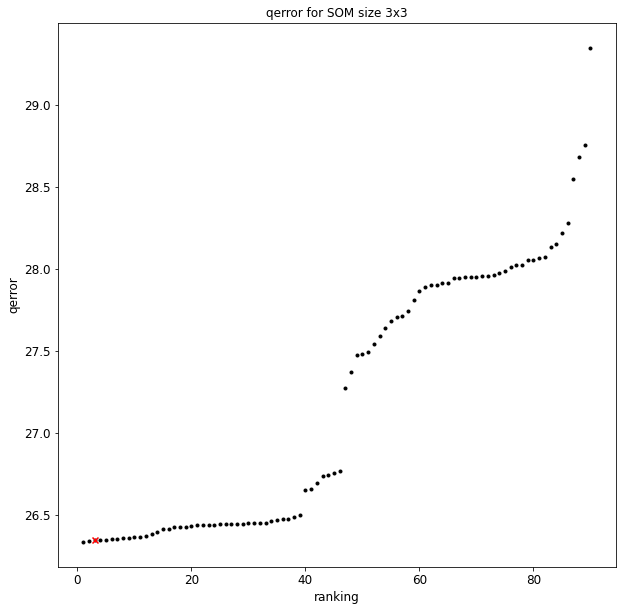

In [25]:
print('Plotting qerror for som: '+str(som_row)+'x'+str(som_col))

# set output name
fout = 'supp_fig_qerror.png'
label_in = 'qerror for SOM size '+str(som_row)+'x'+str(som_col)
fs=12

# Actually plot figure now
fig = plt.figure(figsize=(10,10))

# plot all SOM qerror
ax = fig.add_subplot(1,1,1)
ax.scatter(xarr_all,qerr_all.values,marker='.',c='black')
ax.scatter(xarr_all[s],qerr_all.values[s],marker='x',c='red')
plt.title(label_in,fontsize=fs)
plt.xlabel('ranking',fontsize=fs)
plt.ylabel('qerror',fontsize=fs)
plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)

# save figure:
fig = plt.savefig(fout, bbox_inches='tight', dpi=200)

## Section 2: Plot Sammon Maps

In [38]:
# load training data to get some info
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/som_training/'

In [39]:
# open training data
fin = dir_in + 'mesaclip_training_data_alaska_psl_autumn_decadal.nc'
subset = xr.open_dataset(fin)

# assign to numpy array object
subsetarray = subset['train_data'].values

# check the data dims/shape - should match the dims from the getting data notebook
print(subsetarray.shape)
# confirm there are no NaN values in array for training (should print False if no values)
print(np.isnan(subsetarray).any())

(49410, 2007)
False


In [40]:
# define shape
input_length = subsetarray.shape[1]

In [41]:
# set: path where the pickles are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/som_training/pickles/psl_som/'

3th lowest qerror
TolFun exceeded: Optimisation terminated


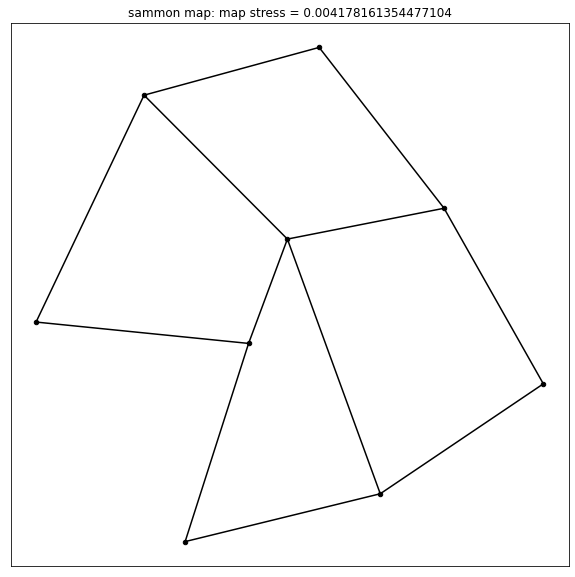

In [46]:
# Loop through the lowest values and load in the relevant pickle

for n in xarr_all[2:3]:
    print(str(n)+'th lowest qerror')
    
    # set the training values
    qerr = sorted_df.iloc[n-1]['q_error'].item()
    sig = sorted_df.iloc[n-1]['sigma'].item()
    lr = sorted_df.iloc[n-1]['lr'].item()
    n_iter = int(sorted_df.iloc[n-1]['n_iter'].item())
    
    # construct the input and output name from this, set as output for figure names
    fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
    fout = 'supp_fig_som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_rank_'+str(n)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)+'.png'    
    
    # open pickle
    with open(dir_in+fin+'.p', 'rb') as infile:
        som = pickle.load(infile)

    # Calculate sammon coordinates (y) for map and "map stress" (E)
    [y,E] = sammon.sammon(som.get_weights().reshape(som_col*som_row, input_length),2,display=1)

    # Plot Sammon map nodes
    fig = plt.figure(figsize=(10,10))
    plt.scatter(y[:,0], y[:,1], s=20, c='black', marker='o')

    # Add lines between nodes
    tmp = np.reshape(y,(som_col,som_row,2))
    len_x, len_y, len_z = tmp.shape
    
    # add vertical lines
    for i in range(len_x-1):
        for j in range(len_y):
            plt.plot(tmp[i:i+2,j,0],tmp[i:i+2,j,1],c='black')
    
    # add horizontal lines
    for i in range(len_x):
        for j in range(len_y-1):
            plt.plot(tmp[i,j:j+2,0],tmp[i,j:j+2,1],c='black')  
    
    plt.xticks([])
    plt.yticks([])
    plt.title(r"sammon map: map stress = "+str(E), fontsize=12)
    
    # save figure
    fig = plt.savefig(fout, bbox_inches='tight', dpi=200)